# SciPulse — 01 · Analyse de qualité du Bronze et procédure de nettoyage

**Module 1 — étape 2 du projet.** Ce notebook :

1. charge les trois sources de la couche **Bronze** (ArXiv, Hacker News, OpenAlex) ;
2. mesure leur qualité (valeurs manquantes, doublons, formats, valeurs aberrantes) ;
3. présente des **statistiques descriptives** et des visualisations ;
4. applique la **procédure de nettoyage** du Silver (`src/silver/cleaning.py`, `src/silver/citations.py`)
   et compare avant / après ;
5. relie chaque anomalie à la règle de nettoyage et à l'expectation Great Expectations qui la contrôle.

Le nettoyage n'est **pas** réécrit ici : le notebook appelle les mêmes fonctions que les tâches Airflow,
ce qui garantit que l'analyse et la production appliquent exactement les mêmes règles.

### Source des données

| `SCIPULSE_NB_SOURCE` | Données lues |
|---|---|
| `fixtures` (défaut) | jeu de test versionné `tests/fixtures/` (75 lignes ArXiv avec anomalies volontaires, items HN, œuvres OpenAlex) |
| `minio` | partitions Bronze réelles dans MinIO (`arxiv-raw`, `hn-raw`, `citations-raw`), après `make up` et un run du DAG |

Les sorties enregistrées dans ce notebook proviennent du **jeu de test** : les volumes sont donc petits,
mais chaque type d'anomalie y est représenté. Relancer avec `SCIPULSE_NB_SOURCE=minio` donne les chiffres du corpus complet.

In [1]:
import json
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("SCIPULSE_MONITORING", "0")      # pas d'événements pipeline-logs depuis le notebook

from src.config import ARXIV_SCOPE_PREFIXES
from src.silver.citations import clean_citations
from src.silver.cleaning import (arxiv_bronze_frame, clean_arxiv, clean_hn, diagnose_arxiv_bronze,
                                 hn_bronze_frame, parse_jsonl)

SOURCE = os.getenv("SCIPULSE_NB_SOURCE", "fixtures")
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("Source :", SOURCE, "| périmètre :", ARXIV_SCOPE_PREFIXES)

Source : fixtures | périmètre : ('cs.', 'stat.ML')


## 1. Chargement de la couche Bronze

In [2]:
json_report = Counter()

if SOURCE == "minio":
    from src.config import BUCKET_ARXIV_RAW
    from src.lake import s3
    from src.quality.samples import citations_bronze_records, hn_bronze_sample, latest_partition

    partition = latest_partition(BUCKET_ARXIV_RAW, "ingest_date")
    lines = []
    for key in s3.list_keys(BUCKET_ARXIV_RAW, f"ingest_date={partition}/", ".jsonl"):
        lines += list(s3.iter_jsonl_lines(BUCKET_ARXIV_RAW, key))
        if len(lines) >= 200_000:
            break
    arxiv_records = parse_jsonl(lines, json_report)
    hn_raw = hn_bronze_sample(50_000)
    hn_items = hn_raw.to_dict("records")
    works = citations_bronze_records(50_000)
else:
    fixtures = PROJECT_ROOT / "tests" / "fixtures"
    lines = (fixtures / "arxiv_bronze.jsonl").read_text(encoding="utf-8").splitlines()
    arxiv_records = parse_jsonl(lines, json_report)
    hn_items = json.loads((fixtures / "hn_items.json").read_text(encoding="utf-8"))
    works = json.loads((fixtures / "openalex_works.json").read_text(encoding="utf-8"))

arxiv_raw = arxiv_bronze_frame(arxiv_records)
hn_raw = hn_bronze_frame(hn_items)
print(f"ArXiv  : {len(lines)} lignes JSONL, {json_report['json_errors']} illisibles, {len(arxiv_raw)} enregistrements")
print(f"HN     : {len(hn_raw)} items")
print(f"OpenAlex : {len(works)} œuvres")
arxiv_raw.head(3)

ArXiv  : 75 lignes JSONL, 1 illisibles, 74 enregistrements
HN     : 6 items
OpenAlex : 66 œuvres


,id,title,abstract,authors,categories,update_date,doi,submitter,journal-ref,license,versions,authors_parsed
0,1702.20001,Corpus dialogue semantic corpus dialogue parsing,corpus parsing transformer language corpus translation translation attenti...,"Bob Chen, Mai Nguyen, Jun Tanaka",cs.CL,2018-09-17,None,Bob Chen,None,http://arxiv.org/licenses/nonexclusive-distrib/1.0/,"[{'version': 'v1', 'created': 'Mon, 26 Jun 2017 10:00:00 GMT'}]","[[Chen, Bob, ], [Nguyen, Mai, ], [Tanaka, Jun, ]]"
1,1704.20002,Parsing semantic dialogue language attention sentence,translation parsing dialogue attention parsing token semantic parsing tran...,"Mai Nguyen, Lea Rossi, Jun Tanaka",cs.CL,2018-09-17,None,Mai Nguyen,None,http://arxiv.org/licenses/nonexclusive-distrib/1.0/,"[{'version': 'v1', 'created': 'Mon, 1 May 2017 10:00:00 GMT'}]","[[Nguyen, Mai, ], [Rossi, Lea, ], [Tanaka, Jun, ]]"
2,1711.20003,Parsing parsing corpus corpus token token,dialogue transformer semantic corpus sentence parsing corpus transformer t...,"Ines Silva, Alice Martin",cs.CL,2018-04-19,None,Ines Silva,None,http://arxiv.org/licenses/nonexclusive-distrib/1.0/,"[{'version': 'v1', 'created': 'Mon, 24 May 2017 10:00:00 GMT'}]","[[Silva, Ines, ], [Martin, Alice, ]]"


## 2. Qualité du Bronze ArXiv

`diagnose_arxiv_bronze` calcule les indicateurs utilisés aussi par le job Silver
(rapport `cleaning_report` envoyé dans `pipeline-logs`).

In [3]:
diag = diagnose_arxiv_bronze(arxiv_raw, ARXIV_SCOPE_PREFIXES)
diag["json_errors"] = json_report["json_errors"]
diag_df = (pd.Series(diag, name="valeur").to_frame()
             .assign(pct=lambda d: (100 * d["valeur"] / max(diag["rows"], 1)).round(2)))
diag_df

,valeur,pct
rows,74,100.00
null_id,0,0.00
null_title,0,0.00
null_abstract,1,1.35
null_categories,0,0.00
null_update_date,0,0.00
null_doi,72,97.30
null_authors,0,0.00
duplicate_ids,1,1.35
bad_date_format,1,1.35


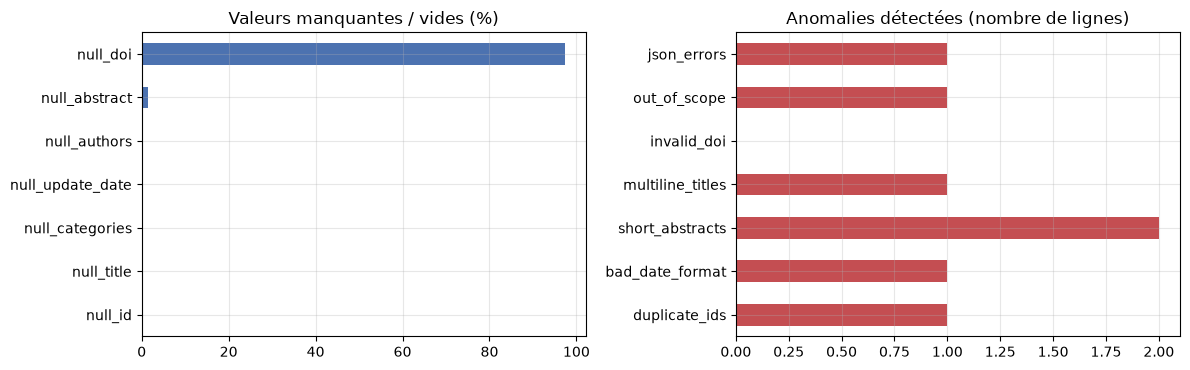

In [4]:
nulls = diag_df.loc[[i for i in diag_df.index if i.startswith("null_")], "pct"].sort_values()
anomalies = diag_df.loc[["duplicate_ids", "bad_date_format", "short_abstracts", "multiline_titles",
                         "invalid_doi", "out_of_scope", "json_errors"], "valeur"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
nulls.plot.barh(ax=axes[0], color="#4C72B0", title="Valeurs manquantes / vides (%)")
anomalies.plot.barh(ax=axes[1], color="#C44E52", title="Anomalies détectées (nombre de lignes)")
plt.tight_layout()

**Lecture.** Le DOI est la colonne la plus souvent absente : c'est *normal* (beaucoup de prépublications
n'ont pas de DOI d'éditeur). C'est pour cette raison que la jointure avec OpenAlex utilise d'abord le DOI
ArXiv `10.48550/arxiv.<id>` (attribué à tous les articles par DataCite) puis, en second, le DOI d'éditeur.
Les autres anomalies (doublons d'identifiant, abstracts vides ou très courts, titres sur plusieurs lignes,
dates mal formées, catégories hors périmètre, lignes JSON illisibles) sont corrigées ou filtrées au Silver.

## 3. Statistiques descriptives ArXiv

In [5]:
valid = arxiv_raw.dropna(subset=["abstract"]).copy()
valid["abstract_len"] = valid["abstract"].astype(str).str.strip().str.len()
valid["n_authors"] = valid["authors_parsed"].map(lambda a: len(a) if isinstance(a, list) else None)
valid["year"] = pd.to_datetime(valid["update_date"], errors="coerce").dt.year
valid[["abstract_len", "n_authors", "year"]].describe().round(1)

,abstract_len,n_authors,year
count,74.0,74.0,73.0
mean,616.4,2.0,2022.1
std,168.9,0.8,3.2
min,0.0,1.0,2002.0
25%,541.2,1.0,2022.0
50%,632.5,2.0,2023.0
75%,723.8,3.0,2024.0
max,889.0,3.0,2024.0


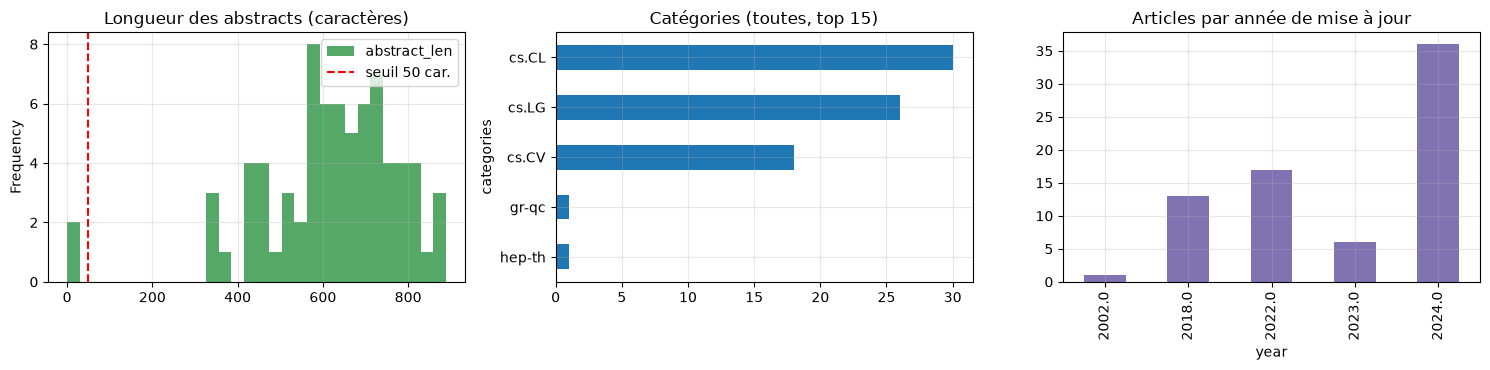

In [6]:
cats = (arxiv_raw["categories"].dropna().astype(str).str.split()
        .explode().value_counts().head(15))
primary = arxiv_raw["categories"].dropna().astype(str).str.split().str[0].value_counts().head(10)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
valid["abstract_len"].plot.hist(bins=30, ax=axes[0], color="#55A868", title="Longueur des abstracts (caractères)")
axes[0].axvline(50, color="red", ls="--", label="seuil 50 car.")
axes[0].legend()
cats.sort_values().plot.barh(ax=axes[1], title="Catégories (toutes, top 15)")
valid["year"].value_counts().sort_index().plot.bar(ax=axes[2], color="#8172B2",
                                                   title="Articles par année de mise à jour")
plt.tight_layout()

**Lecture.** La distribution des longueurs d'abstract est asymétrique ; les valeurs sous 50 caractères
sont des abstracts tronqués ou des placeholders (« withdrawn », « see paper ») : ils sont conservés mais
**signalés** (`abstract_too_short`) plutôt que supprimés, car le titre reste exploitable.
Les catégories confirment le périmètre `cs.*` + `stat.ML` ; les articles d'autres domaines sont écartés au Silver.

## 4. Qualité du Bronze Hacker News

In [7]:
hn_quality = pd.Series({
    "items": len(hn_raw),
    "id manquant": int(hn_raw["id"].isna().sum()),
    "supprimés (deleted)": int(hn_raw["deleted"].eq(True).sum()),
    "masqués (dead)": int(hn_raw["dead"].eq(True).sum()),
    "doublons d'id (relus à plusieurs cycles)": int(hn_raw["id"].dropna().duplicated().sum()),
    "stories sans titre": int(((hn_raw["type"] == "story") & hn_raw["title"].isna()).sum()),
    "texte HTML": int(hn_raw["text"].dropna().astype(str).str.contains("<").sum()),
}, name="valeur").to_frame()
hn_quality

,valeur
items,6
id manquant,0
supprimés (deleted),1
masqués (dead),0
doublons d'id (relus à plusieurs cycles),0
stories sans titre,1
texte HTML,1


Items mentionnant un lien arxiv.org : 4 / 6


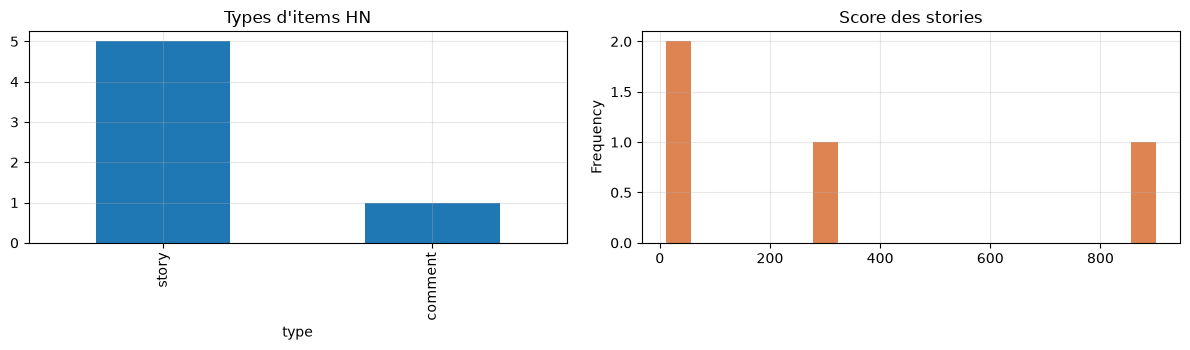

In [8]:
links = hn_raw["url"].fillna("").str.contains("arxiv.org") | hn_raw["text"].fillna("").str.contains("arxiv.org")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
hn_raw["type"].fillna("(inconnu)").value_counts().plot.bar(ax=axes[0], title="Types d'items HN")
stories = hn_raw[hn_raw["type"] == "story"]
pd.to_numeric(stories["score"], errors="coerce").dropna().plot.hist(bins=20, ax=axes[1], color="#DD8452",
                                                                   title="Score des stories")
plt.tight_layout()
print(f"Items mentionnant un lien arxiv.org : {int(links.sum())} / {len(hn_raw)}")

## 5. Qualité du Bronze OpenAlex (citations)

,valeur
œuvres,66
id manquant,0
DOI manquant,0
DOI ArXiv (10.48550),65
cited_by_count invalide,0
doublons d'id,0


<Axes: title={'center': 'Citations par œuvre (distribution à longue traîne)'}, ylabel='Frequency'>

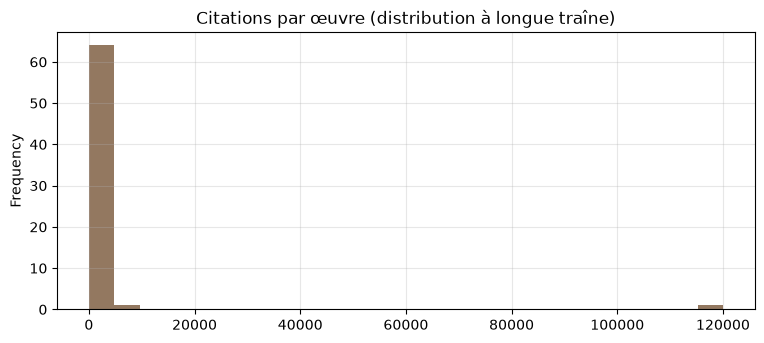

In [9]:
oa = pd.DataFrame({
    "id": [w.get("id") for w in works],
    "doi": [w.get("doi") for w in works],
    "cited_by_count": [w.get("cited_by_count") for w in works],
    "n_years": [len(w.get("counts_by_year") or []) for w in works],
})
oa_quality = pd.Series({
    "œuvres": len(oa),
    "id manquant": int(oa["id"].isna().sum()),
    "DOI manquant": int(oa["doi"].isna().sum()),
    "DOI ArXiv (10.48550)": int(oa["doi"].fillna("").str.lower().str.contains("10.48550/arxiv").sum()),
    "cited_by_count invalide": int(oa["cited_by_count"].map(lambda v: not isinstance(v, int) or v < 0).sum()),
    "doublons d'id": int(oa["id"].dropna().duplicated().sum()),
}, name="valeur").to_frame()
display(oa_quality)
pd.to_numeric(oa["cited_by_count"], errors="coerce").dropna().plot.hist(
    bins=25, color="#937860", title="Citations par œuvre (distribution à longue traîne)")

**Lecture.** Les citations suivent une loi à longue traîne : quelques articles concentrent l'essentiel
des citations. C'est la raison pour laquelle le score d'impact du Module 2 utilise `log(1 + citations)`
normalisé **par cohorte catégorie × année** (voir `docs/02_pipeline_spark.md`).

## 6. Procédure de nettoyage : avant / après

On applique les fonctions de production. Chaque compteur du rapport correspond à une règle
documentée en tête de `src/silver/cleaning.py`.

In [10]:
arxiv_report = Counter(json_errors=json_report["json_errors"])
arxiv_silver = clean_arxiv(arxiv_records, ARXIV_SCOPE_PREFIXES, arxiv_report)

hn_report = Counter()
hn_silver = clean_hn(hn_items, hn_report)

oa_report = Counter()
citations_silver = clean_citations(works, oa_report)

reports = pd.DataFrame({"ArXiv": pd.Series(arxiv_report), "Hacker News": pd.Series(hn_report),
                        "OpenAlex": pd.Series(oa_report)}).fillna(0).astype(int)
reports

,ArXiv,Hacker News,OpenAlex
arxiv_doi_rows,0,0,65
arxiv_links,0,3,0
deleted_or_dead,0,1,0
duplicates,1,0,0
input,74,6,66
invalid_dates,1,0,0
journal_doi_rows,0,0,1
json_errors,1,0,0
missing_abstract,1,0,0
missing_title,0,0,0


,Bronze (lignes),Silver (lignes),conservé (%)
ArXiv,75,71,94.7
Hacker News,6,5,83.3
OpenAlex,66,66,100.0


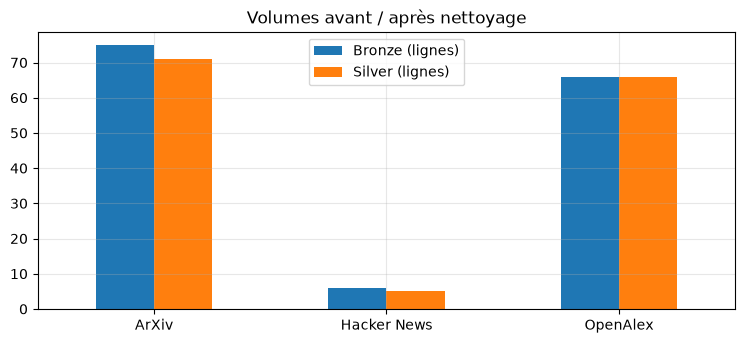

In [11]:
summary = pd.DataFrame({
    "Bronze (lignes)": [len(lines), len(hn_items), len(works)],
    "Silver (lignes)": [len(arxiv_silver), len(hn_silver), len(citations_silver)],
}, index=["ArXiv", "Hacker News", "OpenAlex"])
summary["conservé (%)"] = (100 * summary["Silver (lignes)"] / summary["Bronze (lignes)"]).round(1)
summary.plot.bar(y=["Bronze (lignes)", "Silver (lignes)"], rot=0, title="Volumes avant / après nettoyage")
summary

In [12]:
# Exemple de normalisation : titre multi-lignes, catégories encodées, DOI, date de v1
arxiv_silver[["arxiv_id", "title", "primary_category", "domain", "categories",
              "date_published", "doi", "arxiv_doi", "abstract_too_short"]].head(5)

,arxiv_id,title,primary_category,domain,categories,date_published,doi,arxiv_doi,abstract_too_short
0,1701.20005,Transformer language language attention dialogue parsing,cs.CL,cs,[cs.CL],2017-11-17 10:00:00+00:00,None,10.48550/arxiv.1701.20005,False
1,1702.20001,Corpus dialogue semantic corpus dialogue parsing,cs.CL,cs,[cs.CL],2017-06-26 10:00:00+00:00,None,10.48550/arxiv.1702.20001,False
2,1703.20011,Translation token dialogue attention language language,cs.CL,cs,[cs.CL],2017-01-27 10:00:00+00:00,None,10.48550/arxiv.1703.20011,False
3,1704.20002,Parsing semantic dialogue language attention sentence,cs.CL,cs,[cs.CL],2017-05-01 10:00:00+00:00,None,10.48550/arxiv.1704.20002,False
4,1706.03762,Attention Is All You Need,cs.CL,cs,"[cs.CL, cs.LG]",2017-06-10 10:00:00+00:00,None,10.48550/arxiv.1706.03762,False


In [13]:
# Lien Hacker News → ArXiv détecté au Silver (clé de jointure du Module 2)
hn_silver.loc[hn_silver["arxiv_id_linked"].notna(),
              ["hn_id", "post_type", "title", "score", "arxiv_id_linked", "arxiv_link_source"]]

,hn_id,post_type,title,score,arxiv_id_linked,arxiv_link_source
0,41000001,article,GPT-4 Technical Report,900,2303.08774,url
1,41000002,article,Scaling laws for sparse MoE,300,2305.10001,url
3,41000004,ask_hn,Ask HN: which papers do you read?,12,2303.08774,text


In [14]:
citations_silver[["openalex_id", "doi", "arxiv_id", "match_key_type", "cited_by_count", "field"]].head(5)

,openalex_id,doi,arxiv_id,match_key_type,cited_by_count,field
0,W3000000000,10.48550/arxiv.1701.20005,1701.20005,arxiv_doi,9,Computer Science
1,W3000000001,10.48550/arxiv.1702.20001,1702.20001,arxiv_doi,23,Computer Science
2,W3000000002,10.48550/arxiv.1703.20011,1703.20011,arxiv_doi,12,Computer Science
3,W3000000003,10.48550/arxiv.1704.20002,1704.20002,arxiv_doi,20,Computer Science
4,W3000000004,10.48550/arxiv.1706.03762,1706.03762,arxiv_doi,120000,Computer Science


## 7. Des anomalies aux règles et aux expectations

| Anomalie observée au Bronze | Règle Silver | Expectation qui la contrôle |
|---|---|---|
| Lignes JSON illisibles | rejet + compteur `json_errors` | — (contrôlée au parsing, compteur dans `pipeline-logs`) |
| Hors périmètre (ni `cs.*` ni `stat.ML`) | rejet | Silver : `expect_column_values_to_be_in_set(primary_category)` et `(domain)` |
| Identifiant absent ou en double | rejet / garde la version la plus récente | Bronze : `not_be_null(id)`, `be_unique(id)` · Silver : `not_be_null(arxiv_id)`, `be_unique(arxiv_id)`, `match_regex(arxiv_id)` (sans suffixe de version) |
| Titre / abstract vide | rejet | Silver : `not_be_null(title)`, `not_be_null(abstract)` |
| Abstract < 50 caractères | conservé, `abstract_too_short = True` | Bronze : `value_lengths_to_be_between(abstract, min 50, mostly 0.95)` · Silver : `be_between(abstract_length, min 50, mostly 0.95)` |
| Titres multi-lignes, espaces multiples | normalisation (`clean_text`) | — (vérifiée par `tests/unit/test_silver_cleaning.py`) ; Silver : `value_lengths_to_be_between(title, min 10)` |
| Dates texte, formats variés | timestamps UTC, date de publication = v1 | Bronze : `match_regex(update_date, AAAA-MM-JJ)` · Silver : `not_be_null(date_published)`, `be_between(year_published, 1991, année courante)` |
| DOI avec préfixe `https://doi.org/`, casse variable | minuscules, sans préfixe | Bronze : `match_regex(doi, ^10\.)` (mostly) · Silver : `match_regex(doi)`, `match_regex(arxiv_doi, ^10\.48550/arxiv\.)` |
| HN : items supprimés / masqués | rejet | Bronze : `be_null(deleted)`, `be_null(dead)` (mostly 0.98, diagnostic) |
| HN : item relu à plusieurs cycles | garde la mesure la plus récente | Silver : `be_unique(hn_id)` |
| HN : score porté par un commentaire | score mis à null hors stories / jobs / polls | Silver : `be_null(score)` si `type == "comment"` |
| OpenAlex : œuvre sans DOI | rejet (inutilisable pour la jointure) | Silver : `not_be_null(doi)` |
| OpenAlex : DOI en majuscules (`10.48550/arXiv.…`) | DOI en minuscules | Silver : `match_regex(doi, ^[^A-Z]+$)` |
| OpenAlex : compte de citations négatif ou non entier | rejet | Silver : `be_between(cited_by_count, min 0)` |

(Noms abrégés : `not_be_null` = `expect_column_values_to_not_be_null`, etc.)

Les suites complètes sont versionnées dans `gx/expectations/` (12 + 16 expectations ArXiv, 10 + 11 HN,
10 citations) et définies dans `src/quality/validate_*.py`. Les suites **Bronze** sont des diagnostics
(un échec est attendu et documenté dans les Data Docs) ; les suites **Silver** sont des contrats : un échec
arrête le DAG avant que la donnée n'atteigne Elasticsearch.

## 8. Conclusions

- La qualité brute est hétérogène selon la source ; les problèmes majeurs sont les doublons (ArXiv et HN,
  ce dernier par construction du micro-batch), les champs vides et des formats non normalisés (dates, DOI).
- Le DOI d'éditeur est trop souvent absent pour servir seul de clé de jointure : le DOI ArXiv DataCite le complète.
- Les distributions à longue traîne (citations, scores HN) imposent une transformation logarithmique
  avant toute agrégation dans un score.
- Le nettoyage est réalisé par des fonctions pures, testées (`tests/unit/test_silver_cleaning.py`) et
  partagées entre ce notebook et les tâches Airflow.